# Diagnostics
## How much of the result is signal, and how much is one lucky path?

Notebook 1 produced a single walk-forward number. This one asks how much to
trust it, along four lines:

1. **Combinatorial purged CV** — 15 splits reassembled into **5 complete
   backtest paths**, giving a *distribution* where walk-forward gives a point.
2. **Stability through time** — rolling rank IC across the whole sample, which
   separates "the edge decayed" from "we overfit".
3. **SHAP** — feature importance on the held-out set, as the brief requires.
4. **Per-fold detail** — where the pooled number came from.

In [1]:
import os, sys, json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebooks live in modelling/notebooks/, so the repo root is two levels up.
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if not os.path.isdir(os.path.join(ROOT, "data")):
    ROOT = os.path.abspath(os.getcwd())          # already at the root
sys.path.insert(0, ROOT)

DATA = os.path.join(ROOT, "data")
RESULTS = os.path.join(ROOT, "modelling", "results")
FIGS = os.path.join(RESULTS, "figures")
os.makedirs(FIGS, exist_ok=True)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

from modelling.src.metrics import (mae, profit_factor, signal_profit_factor,
                                   rank_ic, daily_ic_series, report,
                                   directional_accuracy_by_quantile)
from modelling.src.splitters import DateGroupedTimeSeriesSplit, CombinatorialPurgedCV
from modelling.src.models import build_roster, wrap, RANDOM_STATE
from modelling.src.baselines import (ZeroPredictor, RandomPredictor,
                                     BestSingleFeature, random_ic_null)
from modelling.src.evaluate import build, cv_oof, fold_scores, run_roster, select_one_se

train = pd.read_csv(f"{DATA}/model_train.csv", parse_dates=["date"]).reset_index(drop=True)
test = pd.read_csv(f"{DATA}/model_test.csv", parse_dates=["date"]).reset_index(drop=True)
FEATURES = json.load(open(f"{DATA}/feature_meta.json"))["selected"]

X_tr, y_tr, d_tr = train[FEATURES], train["target"].values, train["date"].values
X_te, y_te, d_te = test[FEATURES], test["target"].values, test["date"].values

# Training target winsorised at +/-5 sd; every score uses the RAW target.
WINSOR_SD = 5.0
_sd = y_tr.std()
y_tr_w = np.clip(y_tr, -WINSOR_SD * _sd, WINSOR_SD * _sd)

import pickle
meta = json.load(open(f"{RESULTS}/model_meta.json"))
with open(f"{RESULTS}/params.pkl", "rb") as fh:
    saved = pickle.load(fh)
WINNER = saved["winner"]
FINAL_PARAMS = saved["final_params"]
BEST_BY_MODEL = saved["best_params_by_model"]
roster = build_roster(len(FEATURES))
spec = roster[WINNER]
print(f"Selected model from notebook 1: {WINNER}")
print(f"  params: {FINAL_PARAMS}")

Selected model from notebook 1: HistGBM
  params: {'max_leaf_nodes': 15, 'learning_rate': 0.05, 'min_samples_leaf': 100, 'l2_regularization': 10.0}


## 1. Combinatorial purged cross-validation

Walk-forward gives one path: the single history that happened. CPCV splits the
timeline into 6 contiguous blocks and holds out every pair — 15 splits — with
purging and an embargo on **both sides** of each held-out block, since an
interior block leaks in both directions in a way a walk-forward split never has
to handle.

Because each block is held out in 5 of the 15 splits, the predictions reassemble
into **5 complete backtest paths**. The spread across those paths is the honest
uncertainty on the single walk-forward number.

In [2]:
CPCV = CombinatorialPurgedCV(n_groups=6, n_test_groups=2, embargo=5)
print(f"CPCV(6,2): {CPCV.get_n_splits()} splits, {CPCV.n_paths} reassemblable paths")

TOP = list(pd.read_csv(f"{RESULTS}/model_comparison.csv")
           .query("family != 'baseline'").head(4)["model"])
if WINNER not in TOP:
    TOP.append(WINNER)
print(f"Running CPCV on: {', '.join(TOP)}\n")

path_maps = CPCV.path_assignments(d_tr)
cpcv_rows, path_store = [], {}

for name in TOP:
    sp = roster[name]
    params = FINAL_PARAMS if name == WINNER else BEST_BY_MODEL[name]
    t0 = time.time()
    # path_id -> accumulated predictions over the whole timeline
    paths = {p: np.full(len(y_tr), np.nan) for p in range(CPCV.n_paths)}
    udates = np.array(sorted(pd.unique(d_tr)))
    blocks = CPCV._blocks(udates)          # same blocks the splitter used
    pos = pd.Series(np.arange(len(udates)), index=udates)
    row_pos = pd.Series(d_tr).map(pos).to_numpy()

    for split_i, (tr, te) in enumerate(CPCV.split(X_tr, y_tr, groups=d_tr)):
        est = build(sp, params); est.fit(X_tr.iloc[tr], y_tr_w[tr])
        p = est.predict(X_tr.iloc[te])
        for blk, path_id in path_maps[split_i].items():
            sel = np.isin(row_pos[te], blocks[blk])
            paths[path_id][te[sel]] = p[sel]

    ics = []
    for pid, pv in paths.items():
        msk = np.isfinite(pv)
        ic, t, nd, _ = rank_ic(y_tr[msk], pv[msk], d_tr[msk])
        ics.append(ic)
    path_store[name] = paths
    cpcv_rows.append({"model": name, "mean": np.mean(ics), "sd": np.std(ics, ddof=1),
                      "min": np.min(ics), "max": np.max(ics),
                      "paths_positive": int(np.sum(np.asarray(ics) > 0)),
                      "secs": time.time() - t0,
                      **{f"path_{i}": v for i, v in enumerate(ics)}})
    print(f"  {name:14s} paths {' '.join(f'{v:+.4f}' for v in ics)}   "
          f"mean {np.mean(ics):+.4f} sd {np.std(ics, ddof=1):.4f}  [{time.time()-t0:.0f}s]")

cpcv = pd.DataFrame(cpcv_rows)
cpcv.to_csv(f"{RESULTS}/cpcv_paths.csv", index=False)
print("\nThe SD across paths is the uncertainty the single walk-forward number hides.")

CPCV(6,2): 15 splits, 5 reassemblable paths
Running CPCV on: HistGBM, KerasMLP, LightGBM, RandomForest



  HistGBM        paths +0.0244 +0.0307 +0.0295 +0.0342 +0.0280   mean +0.0294 sd 0.0036  [10s]


  KerasMLP       paths +0.0070 +0.0230 +0.0383 +0.0352 +0.0176   mean +0.0242 sd 0.0129  [50s]


  LightGBM       paths +0.0115 +0.0212 +0.0242 +0.0388 +0.0262   mean +0.0244 sd 0.0098  [12s]


  RandomForest   paths +0.0074 +0.0257 +0.0254 +0.0334 +0.0332   mean +0.0250 sd 0.0106  [7s]

The SD across paths is the uncertainty the single walk-forward number hides.


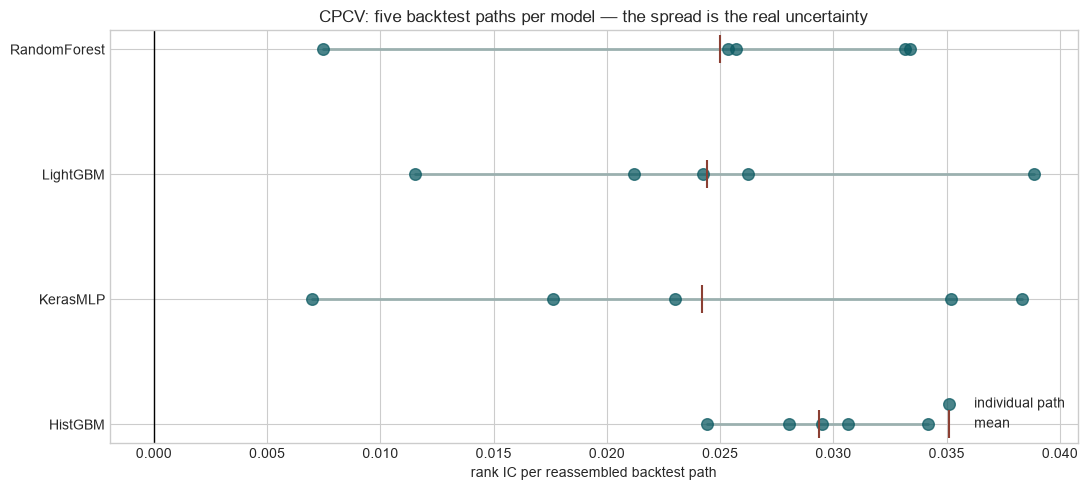

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
pcols = [c for c in cpcv.columns if c.startswith("path_")]
for i, row in cpcv.iterrows():
    ax.scatter(row[pcols].values, [i] * len(pcols), s=70, color="#0D5B63",
               alpha=.75, zorder=3, label="individual path" if i == 0 else None)
    ax.plot([row["min"], row["max"]], [i, i], color="#9BB0AF", lw=2, zorder=2)
    ax.scatter([row["mean"]], [i], marker="|", s=400, color="#8B3F33",
               zorder=4, label="mean" if i == 0 else None)
ax.set_yticks(range(len(cpcv))); ax.set_yticklabels(cpcv["model"])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("rank IC per reassembled backtest path")
ax.set_title("CPCV: five backtest paths per model — the spread is the real uncertainty")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(f"{FIGS}/cpcv_paths.png", dpi=140, bbox_inches="tight"); plt.show()

## 2. Did the edge decay, or was it never there?

Every model went negative on the test set. Two explanations fit that, and they
have very different implications for the write-up:

- **Overfitting** — the validation edge was never real, and the test set simply
  revealed it.
- **Regime shift** — the relationships held in the training window and stopped
  holding afterwards.

A rolling rank IC across the whole sample distinguishes them. Under
overfitting, out-of-fold IC hovers near zero throughout. Under a regime shift,
it is positive through the training window and turns over.

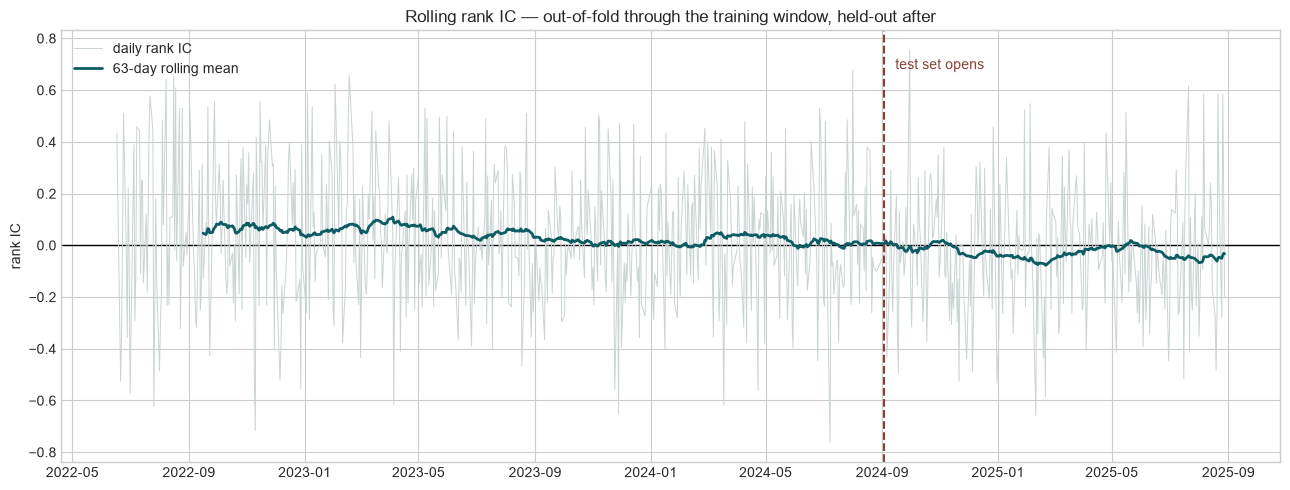

mean daily IC, out-of-fold (train window): +0.0375  over 550 days
mean daily IC, held-out test             : -0.0283  over 248 days

by calendar year:
        mean    std  count
2022  0.0515 0.3115    136
2023  0.0408 0.2465    250
2024  0.0001 0.2457    248
2025 -0.0221 0.2392    164


In [4]:
oof = pd.read_csv(f"{RESULTS}/pred_train_oof.csv", parse_dates=["date"])
pte = pd.read_csv(f"{RESULTS}/pred_test.csv", parse_dates=["date"])

ic_tr = daily_ic_series(oof["target"], oof["pred"], oof["date"])
ic_te = daily_ic_series(pte["target"], pte["pred"], pte["date"])
ic_all = pd.concat([ic_tr, ic_te]).sort_index()

W = 63   # one quarter
roll = ic_all.rolling(W).mean()
split_date = pte["date"].min()

fig, ax = plt.subplots(figsize=(13, 5))
ax.axhline(0, color="black", lw=1)
ax.plot(ic_all.index, ic_all.values, color="#C9D4D3", lw=.7, label="daily rank IC")
ax.plot(roll.index, roll.values, color="#0D5B63", lw=2, label=f"{W}-day rolling mean")
ax.axvline(split_date, color="#8B3F33", ls="--", lw=1.5)
ax.annotate("test set opens", xy=(split_date, ax.get_ylim()[1] * .82),
            xytext=(8, 0), textcoords="offset points", color="#8B3F33", fontsize=10)
ax.set_ylabel("rank IC"); ax.legend(loc="upper left")
ax.set_title("Rolling rank IC — out-of-fold through the training window, held-out after")
plt.tight_layout()
plt.savefig(f"{FIGS}/rolling_ic.png", dpi=140, bbox_inches="tight"); plt.show()

print(f"mean daily IC, out-of-fold (train window): {ic_tr.mean():+.4f}  "
      f"over {len(ic_tr)} days")
print(f"mean daily IC, held-out test             : {ic_te.mean():+.4f}  "
      f"over {len(ic_te)} days")
print(f"\nby calendar year:")
print(ic_all.groupby(ic_all.index.year).agg(["mean", "std", "count"])
      .to_string(float_format=lambda x: f"{x:.4f}"))

## 3. SHAP — feature importance on the held-out set

The brief asks for SHAP values on the testing set. A model-agnostic
`PermutationExplainer` is used rather than `TreeExplainer`, because the
estimator is a `TransformedTargetRegressor` wrapping a pipeline — explaining
`predict` end-to-end attributes importance in the units the strategy actually
consumes, and keeps this cell correct whichever family won.

In [5]:
import shap

final = build(spec, FINAL_PARAMS)
final.fit(X_tr, y_tr_w)

rng = np.random.default_rng(RANDOM_STATE)
bg_idx = rng.choice(len(X_tr), size=min(100, len(X_tr)), replace=False)
ex_idx = rng.choice(len(X_te), size=min(300, len(X_te)), replace=False)
background = X_tr.iloc[bg_idx].fillna(X_tr.median())
explain_on = X_te.iloc[ex_idx].fillna(X_tr.median())

t0 = time.time()
explainer = shap.PermutationExplainer(final.predict, background)
sv = explainer(explain_on, max_evals=2 * len(FEATURES) + 1, silent=True)
print(f"SHAP over {len(explain_on)} test rows in {time.time()-t0:.0f}s")

imp = (pd.DataFrame({"feature": FEATURES,
                     "mean_abs_shap": np.abs(sv.values).mean(axis=0)})
       .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
imp.to_csv(f"{RESULTS}/shap_importance.csv", index=False)
print("\nTop 15 by mean |SHAP| on the test set:\n")
print(imp.head(15).to_string(index=False, float_format=lambda x: f"{x:.6f}"))

BAR = set(json.load(open(f"{DATA}/feature_meta.json"))["bar"])
imp["bucket"] = ["bar" if f.replace("z_", "") in BAR else "exogenous/calendar"
                 for f in imp["feature"]]
share = imp.groupby("bucket")["mean_abs_shap"].sum()
print(f"\nShare of total importance:  "
      + "  ".join(f"{k} {v/share.sum():.0%}" for k, v in share.items()))

SHAP over 300 test rows in 13s

Top 15 by mean |SHAP| on the test set:

       feature  mean_abs_shap
         z_dtc       0.000981
      z_roc_10       0.000643
  z_opt_spread       0.000639
 z_sect_rel_21       0.000571
       z_iv_rv       0.000559
      z_rsi_14       0.000545
       z_mom_5       0.000536
       z_atr_c       0.000518
z_stock_spread       0.000512
     z_iv_skew       0.000493
      z_cmma_5       0.000472
    z_gex_norm       0.000470
      z_iv_30d       0.000458
      z_relvol       0.000457
      z_pc_vol       0.000432

Share of total importance:  bar 40%  exogenous/calendar 60%


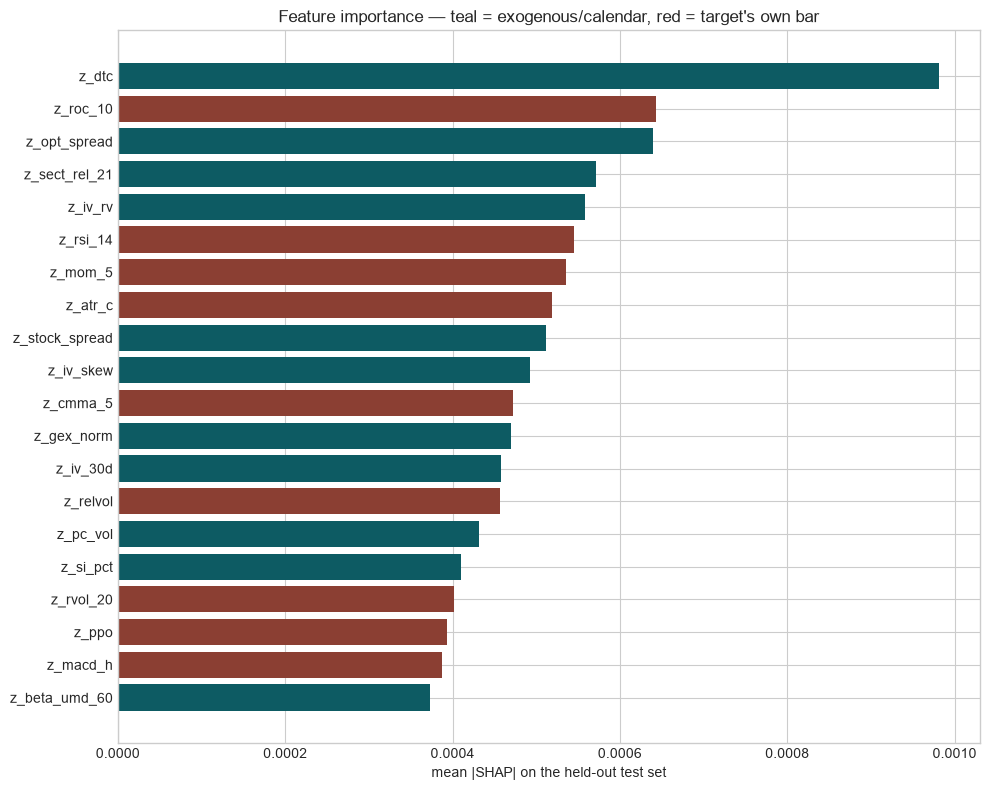

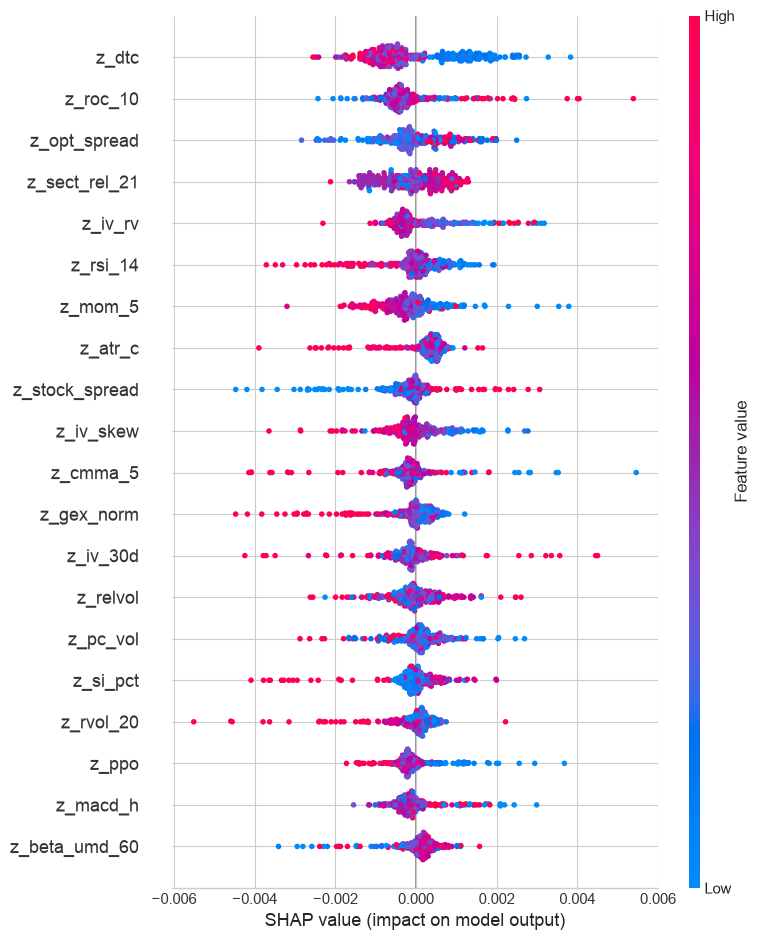

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
top = imp.head(20).iloc[::-1]
cols = ["#8B3F33" if b == "bar" else "#0D5B63" for b in top["bucket"]]
ax.barh(top["feature"], top["mean_abs_shap"], color=cols)
ax.set_xlabel("mean |SHAP| on the held-out test set")
ax.set_title("Feature importance — teal = exogenous/calendar, red = target's own bar")
plt.tight_layout()
plt.savefig(f"{FIGS}/shap_importance.png", dpi=140, bbox_inches="tight"); plt.show()

plt.figure()
shap.summary_plot(sv.values, explain_on, feature_names=FEATURES, show=False, max_display=20)
plt.tight_layout()
plt.savefig(f"{FIGS}/shap_beeswarm.png", dpi=140, bbox_inches="tight"); plt.show()

## 4. Where the pooled number came from

In [7]:
CV = DateGroupedTimeSeriesSplit(n_splits=5, embargo=5)
ics = fold_scores(spec, FINAL_PARAMS, X_tr, y_tr_w, y_tr, d_tr, CV)
folds = []
for k, (tr, va) in enumerate(CV.split(X_tr, y_tr, groups=d_tr)):
    vd = pd.Series(d_tr[va])
    folds.append({"fold": k, "val_from": vd.min().date(), "val_to": vd.max().date(),
                  "val_days": vd.nunique(), "rank_IC": ics[k]})
fd = pd.DataFrame(folds)
print(f"{WINNER} — rank IC computed separately in each fold:\n")
print(fd.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print(f"\nmean {ics.mean():+.4f}   sd {ics.std(ddof=1):.4f}   "
      f"positive in {int((ics>0).sum())}/{len(ics)}")
fd.to_csv(f"{RESULTS}/fold_stability.csv", index=False)

print("\n" + "=" * 70)
print("DIAGNOSTICS COMPLETE")
print("=" * 70)
print(f"  CPCV        : {CPCV.n_paths} paths per model -> modelling/results/cpcv_paths.csv")
print(f"  stability   : rolling IC -> figures/rolling_ic.png")
print(f"  SHAP        : {len(imp)} features -> shap_importance.csv, 2 figures")
print(f"  fold detail : fold_stability.csv")

HistGBM — rank IC computed separately in each fold:

 fold   val_from     val_to  val_days  rank_IC
    0 2022-06-17 2022-11-22       110  +0.0623
    1 2022-11-23 2023-05-03       110  +0.0594
    2 2023-05-04 2023-10-10       110  +0.0268
    3 2023-10-11 2024-03-19       110  +0.0302
    4 2024-03-20 2024-08-26       110  +0.0089

mean +0.0375   sd 0.0228   positive in 5/5

DIAGNOSTICS COMPLETE
  CPCV        : 5 paths per model -> modelling/results/cpcv_paths.csv
  stability   : rolling IC -> figures/rolling_ic.png
  SHAP        : 38 features -> shap_importance.csv, 2 figures
  fold detail : fold_stability.csv
